In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("Food_Delivery_Times.csv")

In [ ]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [ ]:
df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


In [ ]:
# Imputing missing values for categorical columns using their mode
for col in ['Weather', 'Traffic_Level', 'Time_of_Day']:
    df[col] = df[col].fillna(df[col].mode()[0])

# Imputing missing values for Courier_Experience_yrs using its median
# (Note: Preparation_Time_min has 0 missing values based on the earlier null check)
df['Courier_Experience_yrs'] = df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].median())

# Dropping the Order_ID column
df = df.drop(columns=['Order_ID'])

# Check if there are any remaining null values
print(df.isnull().sum())
print("\nRemaining columns in the dataset:", df.columns.tolist())

Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64

Remaining columns in the dataset: ['Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']


In [ ]:
df.duplicated().sum()

np.int64(0)

### 1. Target Variable Distribution: `Delivery_Time_min`

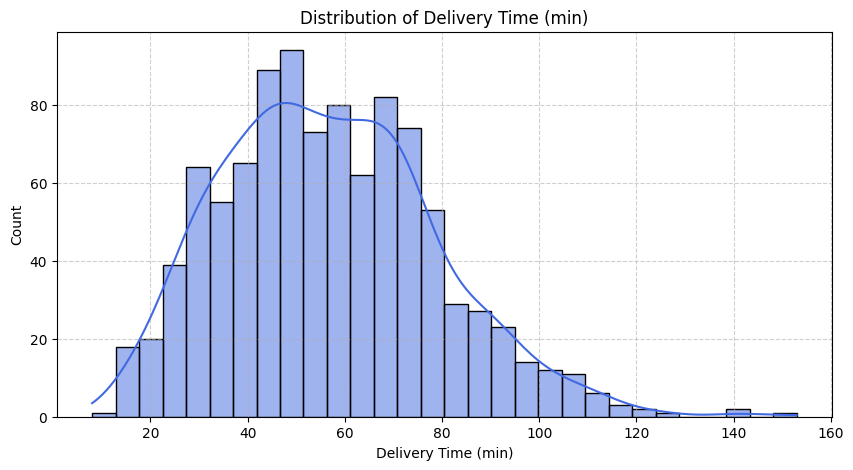

count    1000.000000
mean       56.732000
std        22.070915
min         8.000000
25%        41.000000
50%        55.500000
75%        71.000000
max       153.000000
Name: Delivery_Time_min, dtype: float64


In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Delivery_Time_min'], kde=True, bins=30, color='royalblue')
plt.title('Distribution of Delivery Time (min)')
plt.xlabel('Delivery Time (min)')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(df['Delivery_Time_min'].describe())

### 2. Numerical Features vs. `Delivery_Time_min`
Let's analyze the relationship between numerical features (`Distance_km`, `Preparation_Time_min`, `Courier_Experience_yrs`) and our target.

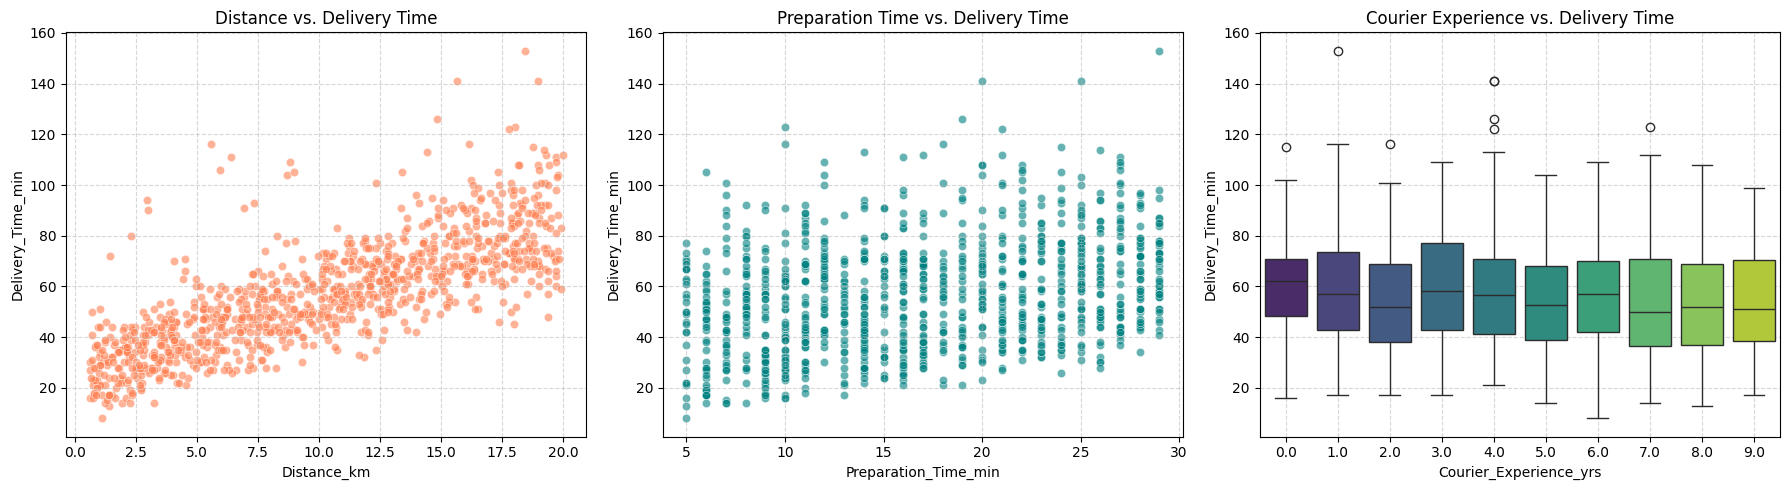

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distance vs Delivery Time
sns.scatterplot(ax=axes[0], x='Distance_km', y='Delivery_Time_min', data=df, alpha=0.6, color='coral')
axes[0].set_title('Distance vs. Delivery Time')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Preparation Time vs Delivery Time
sns.scatterplot(ax=axes[1], x='Preparation_Time_min', y='Delivery_Time_min', data=df, alpha=0.6, color='teal')
axes[1].set_title('Preparation Time vs. Delivery Time')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Courier Experience vs Delivery Time
sns.boxplot(ax=axes[2], x='Courier_Experience_yrs', y='Delivery_Time_min', data=df, palette='viridis')
axes[2].set_title('Courier Experience vs. Delivery Time')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 3. Categorical Features vs. `Delivery_Time_min`
Let's observe how categorical variables like `Weather`, `Traffic_Level`, `Time_of_Day`, and `Vehicle_Type` impact the delivery time.

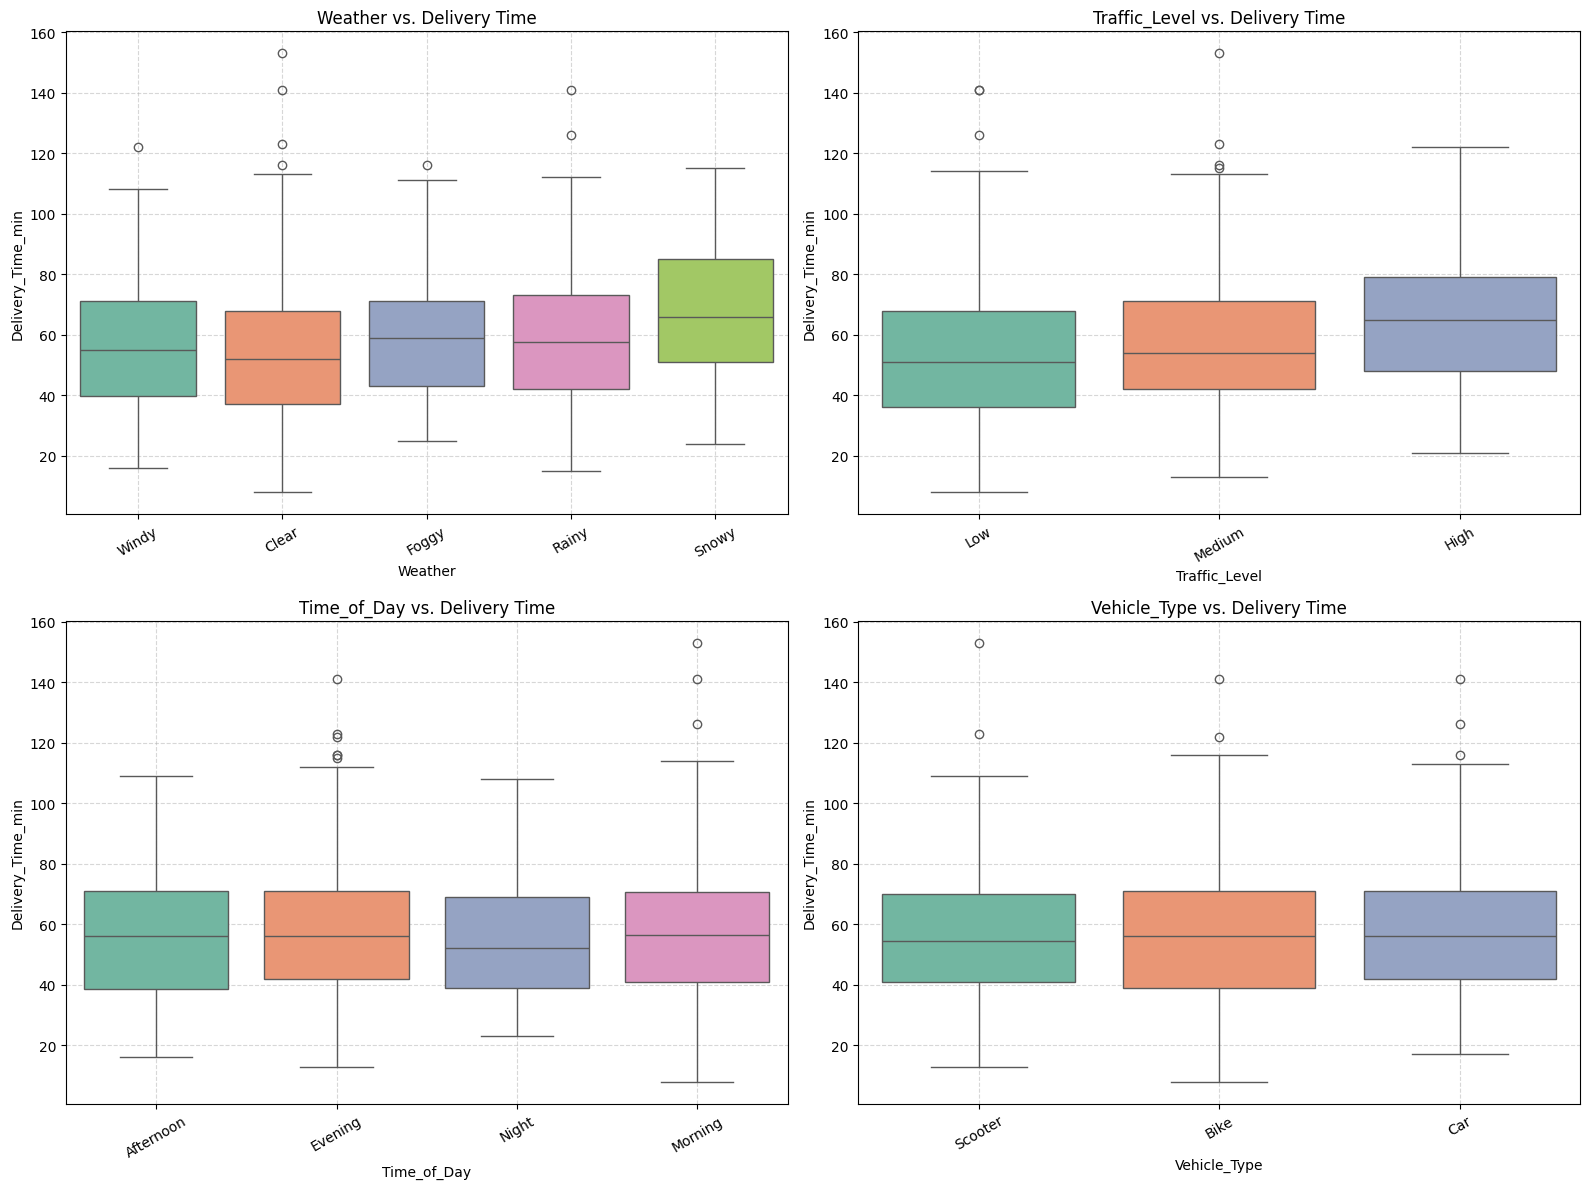

In [ ]:
categorical_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.boxplot(ax=axes[i], x=col, y='Delivery_Time_min', data=df, palette='Set2')
    axes[i].set_title(f'{col} vs. Delivery Time')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

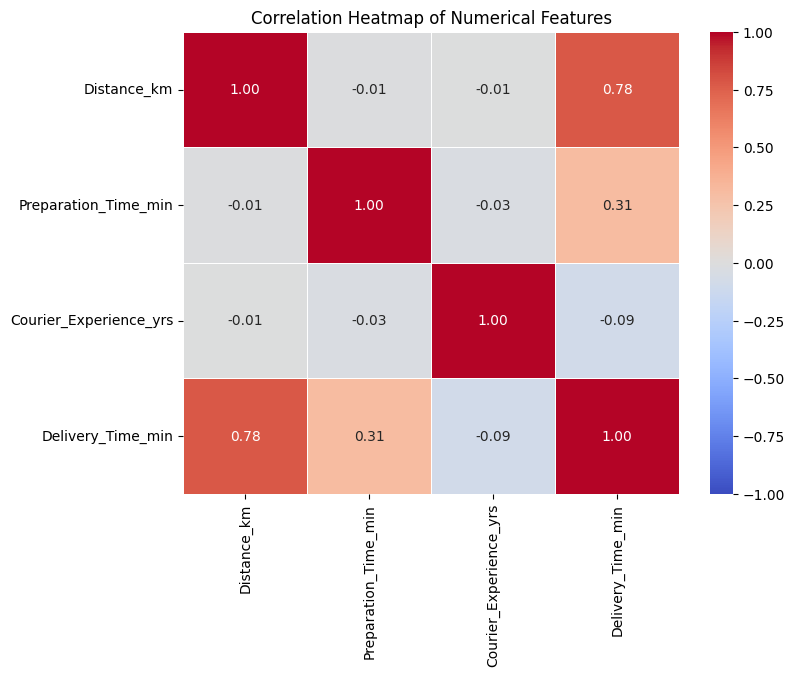

In [ ]:
# Select numerical columns and calculate the correlation matrix
numerical_cols = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']
corr_matrix = df[numerical_cols].corr()

# Plot the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### Statistical Testing for Feature Selection

In [ ]:
import scipy.stats as stats

print("=== 1. Correlation Analysis for Numerical Features ===\n")
numerical_features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
for col in numerical_features:
    coef, p_value = stats.pearsonr(df[col], df['Delivery_Time_min'])
    print(f"{col:25} -> Correlation: {coef:.4f}, p-value: {p_value:.4e} ({'Significant' if p_value < 0.05 else 'Not Significant'})")

=== 1. Correlation Analysis for Numerical Features ===

Distance_km               -> Correlation: 0.7810, p-value: 2.9763e-206 (Significant)
Preparation_Time_min      -> Correlation: 0.3073, p-value: 2.5499e-23 (Significant)
Courier_Experience_yrs    -> Correlation: -0.0891, p-value: 4.8018e-03 (Significant)


In [ ]:
print("=== 2. ANOVA Testing for Categorical Features ===\n")
categorical_features = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
for col in categorical_features:
    # Group delivery times by categories in the column
    groups = [group['Delivery_Time_min'].values for name, group in df.groupby(col)]
    f_stat, p_value = stats.f_oneway(*groups)
    print(f"{col:25} -> F-statistic: {f_stat:.4f}, p-value: {p_value:.4e} ({'Significant' if p_value < 0.05 else 'Not Significant'})")

=== 2. ANOVA Testing for Categorical Features ===

Weather                   -> F-statistic: 10.4991, p-value: 2.4723e-08 (Significant)
Traffic_Level             -> F-statistic: 19.7513, p-value: 3.8697e-09 (Significant)
Time_of_Day               -> F-statistic: 0.3468, p-value: 7.9151e-01 (Not Significant)
Vehicle_Type              -> F-statistic: 0.5894, p-value: 5.5487e-01 (Not Significant)


In [ ]:
df.columns

Index(['Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Distance_km             1000 non-null   float64
 1   Weather                 1000 non-null   object 
 2   Traffic_Level           1000 non-null   object 
 3   Time_of_Day             1000 non-null   object 
 4   Vehicle_Type            1000 non-null   object 
 5   Preparation_Time_min    1000 non-null   int64  
 6   Courier_Experience_yrs  1000 non-null   float64
 7   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(2), object(4)
memory usage: 62.6+ KB


In [ ]:
# 1. Define Features (X) and Target (y)
selected_features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Weather', 'Traffic_Level']
target_col = 'Delivery_Time_min'

X = df[selected_features]
y = df[target_col]

print("Features (X) columns:", X.columns.tolist())
print("Target (y) column:", y.name)

Features (X) columns: ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Weather', 'Traffic_Level']
Target (y) column: Delivery_Time_min


In [ ]:
# 2. Perform Label Encoding on Categorical Columns
from sklearn.preprocessing import LabelEncoder

X_encoded = X.copy()

le_weather = LabelEncoder()
le_traffic = LabelEncoder()

X_encoded['Weather'] = le_weather.fit_transform(X['Weather'])
X_encoded['Traffic_Level'] = le_traffic.fit_transform(X['Traffic_Level'])

print("Weather mapping classes:", list(enumerate(le_weather.classes_)))
print("Traffic Level mapping classes:", list(enumerate(le_traffic.classes_)))
print("\nEncoded features preview:")
display(X_encoded.head())

Weather mapping classes: [(0, 'Clear'), (1, 'Foggy'), (2, 'Rainy'), (3, 'Snowy'), (4, 'Windy')]
Traffic Level mapping classes: [(0, 'High'), (1, 'Low'), (2, 'Medium')]

Encoded features preview:


,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Weather,Traffic_Level
0,7.93,12,1.0,4,1
1,16.42,20,2.0,0,2
2,9.52,28,1.0,1,1
3,7.44,5,1.0,2,2
4,19.03,16,5.0,0,1


In [ ]:
# 3. Perform Train-Test Split (80% Train, 20% Test)
from sklearn.model_selection import train_test_split

X_train_enc, X_test_enc, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print(f"Shape of X_train: {X_train_enc.shape}")
print(f"Shape of X_test:  {X_test_enc.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test:  {y_test.shape}")

Shape of X_train: (800, 5)
Shape of X_test:  (200, 5)
Shape of y_train: (800,)
Shape of y_test:  (200,)


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize the Decision Tree Regressor with default parameters
dt_model = DecisionTreeRegressor(random_state=42)

# Fit the model on our label-encoded training data
dt_model.fit(X_train_enc, y_train)

# Predict on the label-encoded testing data
dt_preds = dt_model.predict(X_test_enc)

# Calculate evaluation metrics
dt_mae = mean_absolute_error(y_test, dt_preds)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_preds))
dt_r2 = r2_score(y_test, dt_preds)

# Print the evaluation metrics
print("=== Decision Tree Regressor (Default Parameters) ===")
print(f"Mean Absolute Error (MAE):      {dt_mae:.4f} minutes")
print(f"Root Mean Squared Error (RMSE):  {dt_rmse:.4f} minutes")
print(f"R-squared (R2 Score):            {dt_r2:.4f}")

=== Decision Tree Regressor (Default Parameters) ===
Mean Absolute Error (MAE):      10.3600 minutes
Root Mean Squared Error (RMSE):  15.0380 minutes
R-squared (R2 Score):            0.4955


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest Regressor with default parameters
rf_model = RandomForestRegressor(random_state=42)

# Fit the model on our label-encoded training data
rf_model.fit(X_train_enc, y_train)

# Predict on the label-encoded testing data
rf_preds = rf_model.predict(X_test_enc)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))
rf_r2 = r2_score(y_test, rf_preds)

# Print the evaluation metrics
print("=== Random Forest Regressor (Default Parameters) ===")
print(f"Mean Absolute Error (MAE):      {rf_mae:.4f} minutes")
print(f"Root Mean Squared Error (RMSE):  {rf_rmse:.4f} minutes")
print(f"R-squared (R2 Score):            {rf_r2:.4f}")

=== Random Forest Regressor (Default Parameters) ===
Mean Absolute Error (MAE):      7.0522 minutes
Root Mean Squared Error (RMSE):  10.0074 minutes
R-squared (R2 Score):            0.7766


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Define the hyperparameter distribution grid
param_dist = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'max_depth': [None, 5, 10, 15, 20, 25],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4, 6],
    'max_features': ['sqrt', 'log2', None]
}

# Initialize RandomizedSearchCV with 100 iterations and 5-fold CV
random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

# Fit the randomized search to the training data
random_search.fit(X_train_enc, y_train)

# Extract the best model
best_rf_random = random_search.best_estimator_
print("Best Parameters Found:", random_search.best_params_)

Best Parameters Found: {'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10}


In [ ]:
# Predict and evaluate using the randomized search tuned model
random_preds = best_rf_random.predict(X_test_enc)

random_mae = mean_absolute_error(y_test, random_preds)
random_rmse = np.sqrt(mean_squared_error(y_test, random_preds))
random_r2 = r2_score(y_test, random_preds)

# Print final evaluation metrics
print("=== RandomizedSearchCV Tuned Random Forest ===")
print(f"Mean Absolute Error (MAE):      {random_mae:.4f} minutes")
print(f"Root Mean Squared Error (RMSE):  {random_rmse:.4f} minutes")
print(f"R-squared (R2 Score):            {random_r2:.4f}")

=== RandomizedSearchCV Tuned Random Forest ===
Mean Absolute Error (MAE):      6.8088 minutes
Root Mean Squared Error (RMSE):  9.4976 minutes
R-squared (R2 Score):            0.7988


In [ ]:
import pickle

# Save the best tuned Random Forest model
with open('best_delivery_rf_model.pkl', 'wb') as model_file:
    pickle.dump(best_rf_random, model_file)

# Save the LabelEncoders used for Weather and Traffic_Level
with open('weather_encoder.pkl', 'wb') as weather_file:
    pickle.dump(le_weather, weather_file)

with open('traffic_encoder.pkl', 'wb') as traffic_file:
    pickle.dump(le_traffic, traffic_file)

print("Successfully saved the following pickle files:")
print("- best_delivery_rf_model.pkl (Tuned Random Forest Model)")
print("- weather_encoder.pkl (LabelEncoder for Weather)")
print("- traffic_encoder.pkl (LabelEncoder for Traffic Level)")

Successfully saved the following pickle files:
- best_delivery_rf_model.pkl (Tuned Random Forest Model)
- weather_encoder.pkl (LabelEncoder for Weather)
- traffic_encoder.pkl (LabelEncoder for Traffic Level)


In [ ]:
import pickle

# Combine the two fitted encoders into a single dictionary
encoders_dict = {
    'Weather': le_weather,
    'Traffic_Level': le_traffic
}

# Save them together into a single pickle file
with open('encoders.pkl', 'wb') as encoders_file:
    pickle.dump(encoders_dict, encoders_file)

print("Successfully saved a single file: encoders.pkl")

Successfully saved a single file: encoders.pkl


### How to load and use the single `encoders.pkl` file:

```python
import pickle
import numpy as np

# Load the single encoders dictionary
with open('encoders.pkl', 'rb') as f:
    encoders = pickle.load(f)

le_weather = encoders['Weather']
le_traffic = encoders['Traffic_Level']

# Example transformation
encoded_weather = le_weather.transform(['Clear'])[0]
encoded_traffic = le_traffic.transform(['Low'])[0]
```

### 6. Code for your Streamlit Frontend (`app.py`)

Create a file named `app.py` in your VS Code workspace, paste the python code below into it, and place `best_delivery_rf_model.pkl` and `encoders.pkl` in the same directory.

To run it, open your terminal and run:
```bash
pip install streamlit scikit-learn numpy pandas
streamlit run app.py
```

In [ ]:
streamlit_code = """
import streamlit as st
import pickle
import numpy as np

# Set page title and styling
st.set_page_config(page_title="Delivery Time Estimator", page_icon="🛵", layout="centered")

st.title("🛵 Food Delivery Time Estimator")
st.write("Enter order details below to estimate delivery time in minutes.")

# 1. Load the model and single unified encoders dictionary
@st.cache_resource
def load_artifacts():
    with open('best_delivery_rf_model.pkl', 'rb') as model_file:
        model = pickle.load(model_file)
    with open('encoders.pkl', 'rb') as encoders_file:
        encoders = pickle.load(encoders_file)
    return model, encoders

try:
    model, encoders = load_artifacts()
    le_weather = encoders['Weather']
    le_traffic = encoders['Traffic_Level']
except Exception as e:
    st.error(f"Error loading pickle files. Make sure 'best_delivery_rf_model.pkl' and 'encoders.pkl' are in the same folder as app.py. Error: {e}")
    st.stop()

# 2. Set up Input Forms
st.subheader("Order & Route Details")

col1, col2 = st.columns(2)

with col1:
    distance = st.number_input("Distance (km)", min_value=0.1, max_value=50.0, value=5.0, step=0.1)
    prep_time = st.number_input("Preparation Time (min)", min_value=1, max_value=120, value=15, step=1)
    courier_exp = st.number_input("Courier Experience (years)", min_value=0.0, max_value=30.0, value=3.0, step=0.5)

with col2:
    # Use the loaded Encoder classes to fill selection box options dynamically
    weather_option = st.selectbox("Weather Condition", options=list(le_weather.classes_))
    traffic_option = st.selectbox("Traffic Level", options=list(le_traffic.classes_))

# 3. Predict Button
if st.button("⚡ Estimate Delivery Time", use_container_width=True):
    # Transform categorical variables
    encoded_weather = le_weather.transform([weather_option])[0]
    encoded_traffic = le_traffic.transform([traffic_option])[0]

    # Arrange input features in the exact training layout:
    # ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Weather', 'Traffic_Level']
    input_features = np.array([[distance, prep_time, courier_exp, encoded_weather, encoded_traffic]])

    # Predict
    prediction = model.predict(input_features)[0]

    # Display Output
    st.success(f"### ⏱️ Estimated Delivery Time: **{prediction:.1f} minutes**")
"""

# Write this code block to a local file inside Colab for the user to easily copy/download
with open('streamlit_app.py', 'w') as f:
    f.write(streamlit_code)
print("A copy of the Streamlit script has also been saved to this runtime as 'streamlit_app.py'")